# ECG Classification Using Traditional Machine Learning
This jupyter notebook contains the full pipeline for loading, feature extraction, training and model evaluation and use of a varied selection of traditional machine learning models.
The notebook is separated into sections for the different parts of the pipeline. For ease of use it is recommended to use the outline section to navigate
and run the different parts of the pipeline. A quick overview is given in the different sections, but the main discussion and analysis is given in the associated report.

## 1. Environment Setup

In [ ]:
# Install required packages from requirements.txt
# Only run this if the required packages are not already installed
# %pip install -r requirements.txt

In [2]:
%load_ext autoreload
%autoreload 2

# ============================================================
# 1. Standard libraries
# ============================================================
import joblib

# ============================================================
# 2. Data handling
# ============================================================
import pandas as pd
import numpy as np

# ============================================================
# 3. Machine learning
# ============================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb

# ============================================================
# 4. Project modules
# ============================================================
from src.data_loading import (
    load_ecg_records,
    prepare_ptbxl_labels
)
from src.filtering import (
    apply_butterworth_filter,
    apply_nk_clean_filter,
    plot_ecg_comparison_slider,
)
from src.feature_extraction import (
    extract_pqrst_dataset,
    extract_dwt_dataset,
    plot_pqrst_landmarks_slider,
    plot_dwt_decomposition,
)
from src.evaluation import (
    clean_and_impute_features,
    compute_clinical_weights,
    compute_multilabel_class_weights,
    evaluate_single_label_cv,
    evaluate_multi_label_cv,
    run_rfecv_selection,
    filter_collinear_features,
    tune_and_evaluate_model,
    plot_confusion_matrix,
    plot_correlation_matrix,
    plot_top_feature_importances,
    evaluate_auroc,
)


In [3]:
# ============================================================
# Global settings
# ============================================================

PATH = "./"
SAMPLING_RATE = 100
RANDOM_STATE = 42
FORCE_RELOAD = False

# Whether to print the Excel row format for evaluation results
PRINT_EXCEL_ROW = False

## 2. Preprocessing

### 2.1 Loading of Dataset

In [4]:
# Paths for cached data
cache_x_path = PATH + "cache/X_cache.npy"
cache_y_path = PATH + "cache/Y_cache.pkl"

Y = load_ecg_records(cache_x_path, cache_y_path, PATH, SAMPLING_RATE=SAMPLING_RATE, FORCE_RELOAD=FORCE_RELOAD)


Cached data found. Number of records: 21799


### 2.2 High-Pass Filter for DWT Feature Extraction Path

In [5]:
# Filter configuration to remove low-frequency baseline wander (< 0.5 Hz)
FILTER_ORDER = 4
CUTOFF_FREQ_HZ = 0.5
FILTER_TYPE = "highpass"

cache_butter_path = PATH + "cache/X_cache_butter_highpass.npy"

apply_butterworth_filter(
    input_cache_path=cache_x_path,
    output_cache_path=cache_butter_path,
    order=FILTER_ORDER,
    cutoff_frequency=CUTOFF_FREQ_HZ,
    btype=FILTER_TYPE,
    sampling_rate=SAMPLING_RATE,
    force_reload=FORCE_RELOAD,
)

Filtered cache already exists at: ./cache/X_cache_butter_highpass.npy


#### 2.2.1 Plot for Comparison of Raw and Filtered Signals

In [5]:
%matplotlib qt

Y = pd.read_pickle(cache_y_path)

# ecg slider is returned to allow interative exploration with plot from imported function
ecg_slider = plot_ecg_comparison_slider(
    raw_cache_path=cache_x_path,
    filtered_cache_path=cache_butter_path,
    Y_df=Y,
    record_index=18232,
    lead=1,
    sampling_rate=SAMPLING_RATE,
    window_seconds=3,
)

## 3. Feature Extraction

In [6]:
# Clinical reference constants and plausible physiological bounds (in ms / seconds)
# Values outside these bounds are treated as delineation artifacts and rejected.
CLINICAL_CONFIG = {
    "ref_lead_idx": 1,               # Reference lead for R-peak detection (Lead II = index 1)
    "st_offset_ms": 60,              # J-point offset for ST-segment shift measurement (ms)
    "qrs_range_ms": (40, 200),       # Plausible QRS complex duration (ms)
    "qt_range_ms":  (200, 600),      # Plausible QT interval duration (ms)
    "pr_range_ms":  (80, 400),       # Plausible PR interval duration (ms)
    "p_range_ms":   (40, 200),       # Plausible P-wave duration (ms)
    "rr_range_sec": (0.3, 2.0),      # Plausible RR interval (0.3s = 200 bpm, 2.0s = 30 bpm)
}

### 3.1 Traditional feature extraction (PQRST)

In [7]:
# This process can take a long time to run
pqrst_cache_path = PATH + "cache/df_features_pqrst.csv"
cache_butter_path = PATH + "cache/X_cache_butter_highpass.npy"

df_features_pqrst = extract_pqrst_dataset(
    filtered_npy_path=cache_butter_path,
    output_csv_path=pqrst_cache_path,
    sampling_rate=SAMPLING_RATE,
    force_reload=FORCE_RELOAD,
    clinical_config=CLINICAL_CONFIG,
)

Loading cached PQRST features from: ./cache/df_features_pqrst.csv


#### 3.1.1 Visualization of PQRST Feature Extraction

In [8]:
%matplotlib qt
# Inspect extracted clinical features and visualize landmarks on a sample record
display(df_features_pqrst.head())

pqrst_slider = plot_pqrst_landmarks_slider(
    filtered_npy_path=cache_butter_path,
    patient_idx=18513,
    lead_idx=1,
    sampling_rate=SAMPLING_RATE,
)

,heart_rate,heart_rate_std,lead1_qrs_duration,lead1_qt_duration,lead1_p_duration,lead1_pr_duration,lead1_r_amplitude,lead1_t_amplitude,lead1_st_shift,lead2_qrs_duration,...,lead11_r_amplitude,lead11_t_amplitude,lead11_st_shift,lead12_qrs_duration,lead12_qt_duration,lead12_p_duration,lead12_pr_duration,lead12_r_amplitude,lead12_t_amplitude,lead12_st_shift
0,63.855440,1.279038,100.0,385.0,60.0,110.0,0.603755,0.002264,-0.066902,100.0,...,0.492385,0.186051,-0.012688,110.0,425.0,80.0,100.0,0.393007,0.160173,-0.012021
1,61.698901,24.969124,150.0,480.0,95.0,155.0,0.560069,0.385544,0.018967,175.0,...,1.601924,0.433294,0.035096,100.0,400.0,90.0,200.0,1.236811,0.364979,0.061171
2,63.785309,1.398491,90.0,410.0,60.0,115.0,0.760223,0.203809,-0.009634,105.0,...,0.706866,0.080788,NaN,100.0,430.0,75.0,105.0,0.577229,0.105689,0.009729
3,75.134259,4.079950,150.0,400.0,60.0,80.0,0.322781,0.303013,-0.044550,115.0,...,1.831413,0.593782,0.045825,90.0,340.0,85.0,130.0,1.332735,0.458640,0.025365
4,66.494641,3.626374,135.0,395.0,50.0,105.0,0.396053,0.163057,-0.026755,110.0,...,1.311811,0.289694,-0.018960,100.0,385.0,80.0,125.0,1.149304,0.233837,-0.009795


### 3.2 DWT Feature Extraction

In [8]:
WAVELET_NAME = "db4"
DECOMPOSITION_LEVEL = 3
dwt_cache_path = PATH + "cache/df_features_dwt.csv"
cache_butter_path = PATH + "cache/X_cache_butter_highpass.npy"

df_features_dwt = extract_dwt_dataset(
    filtered_npy_path=cache_butter_path,
    output_csv_path=dwt_cache_path,
    wavelet=WAVELET_NAME,
    level=DECOMPOSITION_LEVEL,
    force_reload=FORCE_RELOAD,
)

Loading cached DWT features from: ./cache/df_features_dwt.csv


#### 3.2.1 DWT Feature Visualization

In [10]:
display(df_features_dwt.head())

plot_dwt_decomposition(
    filtered_npy_path=cache_butter_path,
    patient_idx=14,
    lead_idx=0,
    wavelet=WAVELET_NAME,
    level=DECOMPOSITION_LEVEL,
)

,Lead1_A_Variance,Lead1_A_Energy,Lead1_A_Entropy,Lead1_A_Max,Lead1_A_Min,Lead1_D3_Variance,Lead1_D3_Energy,Lead1_D3_Entropy,Lead1_D3_Max,Lead1_D3_Min,...,Lead12_D2_Variance,Lead12_D2_Energy,Lead12_D2_Entropy,Lead12_D2_Max,Lead12_D2_Min,Lead12_D1_Variance,Lead12_D1_Energy,Lead12_D1_Entropy,Lead12_D1_Max,Lead12_D1_Min
0,0.027847,3.649100,5.922200,0.466804,-0.221462,0.018824,2.471893,4.775358,0.549855,-0.397479,...,0.003993,1.018347,4.784891,0.298639,-0.247954,0.000214,0.107689,5.190327,0.101648,-0.097608
1,0.092663,12.141297,5.189540,0.996384,-0.314942,0.024869,3.264028,4.294250,0.730717,-0.785449,...,0.039930,10.251661,3.665706,1.249010,-0.893524,0.005680,2.856996,4.054630,0.457021,-0.647695
2,0.044510,5.831097,5.897627,0.541787,-0.331752,0.032861,4.317220,4.325982,0.778971,-0.467201,...,0.006318,1.614894,4.185662,0.486428,-0.435330,0.001089,0.547729,4.563049,0.177141,-0.248017
3,0.062169,8.144224,5.441623,0.725688,-0.377388,0.034756,4.559186,5.038896,0.619068,-0.619411,...,0.089483,22.818155,4.530372,1.385816,-1.404926,0.011735,5.902526,5.190320,0.371837,-0.579923
4,0.020453,2.680930,5.624494,0.409572,-0.212991,0.013393,1.769370,4.447144,0.471857,-0.346836,...,0.027274,6.955803,4.178373,0.970286,-0.768448,0.004201,2.113155,4.606863,0.370496,-0.450127


### 3.3 Combination of Feature Sets

In [9]:
combined_cache_path = PATH + "cache/df_features_combined.csv"

X_features = pd.concat([df_features_pqrst, df_features_dwt], axis=1)
X_features.to_csv(combined_cache_path, index=False)

print(f"Combined Feature Matrix Shape: {X_features.shape}")

Combined Feature Matrix Shape: (21799, 326)


## 4. Label Preprocessing

In [10]:
# Map SCP codes to the 5 diagnostic superclasses and filter out 'UNKNOWN' records
Y = pd.read_pickle(PATH + "cache/Y_cache.pkl")
X_features = pd.read_csv(PATH + "cache/df_features_combined.csv")

(
    X_single,
    Y_single,
    y_encoded,
    y_binarized,
    patient_ids,
    strat_folds,
    encoder,
    mlb,
) = prepare_ptbxl_labels(
    Y_df=Y,
    X_features_df=X_features,
    scp_statements_path=PATH + "scp_statements.csv",
)

print(f"Filtered Dataset Shape: X={X_single.shape}, Y={Y_single.shape}")
print(f"Classes ({len(encoder.classes_)}): {list(encoder.classes_)}\n")
print("Single-Label Superclass Distribution:")
print(Y_single["single_label"].value_counts())

Filtered Dataset Shape: X=(21388, 326), Y=(21388, 29)
Classes (5): ['CD', 'HYP', 'MI', 'NORM', 'STTC']

Single-Label Superclass Distribution:
single_label
NORM    9514
MI      5424
STTC    2817
CD      2325
HYP     1308
Name: count, dtype: int64


## 5. Model evaluation

### 5.1 Initial Model Evaluations

#### 5.1.1 KNN and Decision Tree (Single label)

In [ ]:
X_clean, y_clean, folds_clean = clean_and_impute_features(
    X_single, y_encoded, strat_folds, min_valid_ratio=0.8
)

##### 5.1.1.1 KNN (Baseline)

In [ ]:
model_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=145, n_jobs=-1),
)

y_pred_knn = evaluate_single_label_cv(
    model_knn,
    X_clean,
    y_clean,
    folds_clean,
    encoder.classes_,
    title="KNN Baseline",
)


------ Official PTB-XL Test Fold 10 Classification Report (KNN Baseline) ------
              precision    recall  f1-score   support

          CD       0.77      0.17      0.28       244
         HYP       0.55      0.14      0.22       122
          MI       0.68      0.34      0.45       544
        NORM       0.55      1.00      0.71       962
        STTC       0.49      0.10      0.17       284

    accuracy                           0.57      2156
   macro avg       0.61      0.35      0.37      2156
weighted avg       0.60      0.57      0.50      2156

Overall Accuracy: 57.05%
Macro F1-Score:   0.3658
Feature Count:    326

Excel Row:
326	0.5705	0.5509	0.9958	0.7094	0.6752	0.3401	0.4523	0.4915	0.1021	0.1691	0.5484	0.1393	0.2222	0.7736	0.1680	0.2761


In [15]:

evaluate_auroc(model_knn, X_clean, y_clean, folds_clean, encoder.classes_, title="KNN")


------ AUROC on Test Fold 10 (KNN) ------
AUROC CD: 0.8095
AUROC HYP: 0.8518
AUROC MI: 0.8181
AUROC NORM: 0.8957
AUROC STTC: 0.8438
Macro AUROC: 0.8438


##### 5.1.1.2 Decision Tree (Baseline)

In [16]:
model_dt = DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE)

y_pred_dt = evaluate_single_label_cv(
    model_dt,
    X_clean,
    y_clean,
    folds_clean,
    encoder.classes_,
    title="Decision Tree Baseline",
)



------ Official PTB-XL Test Fold 10 Classification Report (Decision Tree Baseline) ------
              precision    recall  f1-score   support

          CD       0.36      0.30      0.33       244
         HYP       0.25      0.26      0.26       122
          MI       0.51      0.53      0.52       544
        NORM       0.73      0.76      0.74       962
        STTC       0.42      0.38      0.40       284

    accuracy                           0.57      2156
   macro avg       0.46      0.45      0.45      2156
weighted avg       0.56      0.57      0.57      2156

Overall Accuracy: 57.19%
Macro F1-Score:   0.4504
Feature Count:    326

Excel Row:
326	0.5719	0.7254	0.7578	0.7412	0.5133	0.5331	0.5230	0.4192	0.3838	0.4007	0.2540	0.2623	0.2581	0.3650	0.2992	0.3288


#### 5.1.2 XGBoost (Single Label)

In [11]:
# Define clinical multipliers to prioritize pathological classes over NORM
CLINICAL_MULTIPLIERS = {
    "NORM": 0.5,
    "MI": 2.0,
    "CD": 2.0,
    "STTC": 2.0,
    "HYP": 2.0,
}

# Weights are computed from the training folds (1-9) only
train_mask = strat_folds <= 9
balanced_weights = np.zeros(len(y_encoded))
clinical_weights = np.zeros(len(y_encoded))
balanced_weights[train_mask] = compute_clinical_weights(y_encoded[train_mask], encoder)
clinical_weights[train_mask] = compute_clinical_weights(
    y_encoded[train_mask], encoder, clinical_multipliers=CLINICAL_MULTIPLIERS
)

model_xgb = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=RANDOM_STATE,
    eval_metric="mlogloss",
    n_jobs=-1,
)


##### 5.1.2.1 XGBoost (Baseline)

In [18]:
y_pred_xgb_base = evaluate_single_label_cv(
    model_xgb, X_single, y_encoded, strat_folds, encoder.classes_,
    title="XGBoost (Baseline)"
)


------ Official PTB-XL Test Fold 10 Classification Report (XGBoost (Baseline)) ------
              precision    recall  f1-score   support

          CD       0.71      0.42      0.52       245
         HYP       0.51      0.33      0.40       122
          MI       0.66      0.63      0.65       544
        NORM       0.76      0.93      0.84       963
        STTC       0.62      0.53      0.57       284

    accuracy                           0.71      2158
   macro avg       0.65      0.57      0.60      2158
weighted avg       0.70      0.71      0.69      2158

Overall Accuracy: 70.81%
Macro F1-Score:   0.5954
Feature Count:    326

Excel Row:
326	0.7081	0.7615	0.9252	0.8354	0.6571	0.6342	0.6455	0.6224	0.5282	0.5714	0.5128	0.3279	0.4000	0.7083	0.4163	0.5244


#### 5.1.2.2 XGBoost (Balanced)

In [19]:
y_pred_xgb_balanced = evaluate_single_label_cv(
    model_xgb, X_single, y_encoded, strat_folds, encoder.classes_,
    title="XGBoost (Balanced Weights)",
    sample_weight=balanced_weights,
)



------ Official PTB-XL Test Fold 10 Classification Report (XGBoost (Balanced Weights)) ------
              precision    recall  f1-score   support

          CD       0.62      0.53      0.57       245
         HYP       0.41      0.53      0.46       122
          MI       0.70      0.56      0.62       544
        NORM       0.81      0.85      0.83       963
        STTC       0.55      0.66      0.60       284

    accuracy                           0.70      2158
   macro avg       0.62      0.63      0.62      2158
weighted avg       0.70      0.70      0.70      2158

Overall Accuracy: 69.79%
Macro F1-Score:   0.6164
Feature Count:    326

Excel Row:
326	0.6979	0.8119	0.8515	0.8312	0.6957	0.5588	0.6198	0.5484	0.6585	0.5984	0.4062	0.5328	0.4610	0.6190	0.5306	0.5714


#### 5.1.2.3 XGBoost (Weighted)

In [20]:
y_pred_xgb_clinical = evaluate_single_label_cv(
    model_xgb, X_single, y_encoded, strat_folds, encoder.classes_,
    title="XGBoost (Clinical + Balanced Weights)",
    sample_weight=clinical_weights,
)



------ Official PTB-XL Test Fold 10 Classification Report (XGBoost (Clinical + Balanced Weights)) ------
              precision    recall  f1-score   support

          CD       0.47      0.58      0.51       245
         HYP       0.32      0.54      0.40       122
          MI       0.63      0.61      0.62       544
        NORM       0.87      0.64      0.74       963
        STTC       0.46      0.67      0.54       284

    accuracy                           0.62      2158
   macro avg       0.55      0.61      0.56      2158
weighted avg       0.68      0.62      0.64      2158

Overall Accuracy: 62.19%
Macro F1-Score:   0.5627
Feature Count:    326

Excel Row:
326	0.6219	0.8718	0.6355	0.7351	0.6255	0.6140	0.6197	0.4587	0.6655	0.5431	0.3188	0.5410	0.4012	0.4653	0.5755	0.5146


#### 5.1.2.4 XGBoost AUROC (Single Label)

In [21]:
# This cell evaluates the AUROC for the last-fitted XGBoost model. Make sure to re-run the matching evaluation cell first.
print("AUROC for the last-fitted model_xgb (re-run the matching evaluation cell first)")

evaluate_auroc(model_xgb, X_single, y_encoded, strat_folds, encoder.classes_, title="XGBoost")

AUROC for the last-fitted model_xgb (re-run the matching evaluation cell first)

------ AUROC on Test Fold 10 (XGBoost) ------
AUROC CD: 0.8452
AUROC HYP: 0.8646
AUROC MI: 0.8598
AUROC NORM: 0.9205
AUROC STTC: 0.8894
Macro AUROC: 0.8759


### 5.2 Recursive Feature Elimination (RFE)

In [22]:
# Run RFECV (or load cached RFE features)
X_rfe = run_rfecv_selection(
    base_estimator=model_xgb,
    X_df=X_single,
    y_encoded=y_encoded,
    strat_folds=strat_folds,
    output_csv_path=PATH + "cache/df_features_xgb_rfe.csv",
    step=5,
    force_reload=FORCE_RELOAD,
)

y_pred_xgb_rfe = evaluate_single_label_cv(
    model_xgb,
    X_rfe,
    y_encoded,
    strat_folds,
    encoder.classes_,
    title="XGBoost with RFE",
    sample_weight=balanced_weights
)

Loading cached RFE features from: ./cache/df_features_xgb_rfe.csv

------ Official PTB-XL Test Fold 10 Classification Report (XGBoost with RFE) ------
              precision    recall  f1-score   support

          CD       0.60      0.52      0.56       245
         HYP       0.39      0.51      0.44       122
          MI       0.69      0.56      0.62       544
        NORM       0.81      0.85      0.83       963
        STTC       0.56      0.65      0.60       284

    accuracy                           0.70      2158
   macro avg       0.61      0.62      0.61      2158
weighted avg       0.70      0.70      0.69      2158

Overall Accuracy: 69.56%
Macro F1-Score:   0.6105
Feature Count:    286

Excel Row:
286	0.6956	0.8059	0.8536	0.8290	0.6923	0.5625	0.6207	0.5610	0.6479	0.6013	0.3949	0.5082	0.4444	0.6019	0.5184	0.5570


### 5.3 Feature Collinearity Analysis

In [23]:
CORR_THRESHOLD = 0.90

X_uncorrelated = filter_collinear_features(
    X_df=X_single,
    output_csv_path=PATH + "cache/df_features_corr_filtered_090_train_1_9.csv",
    threshold=CORR_THRESHOLD,
    force_reload=FORCE_RELOAD,
)

y_pred_xgb_uncorr = evaluate_single_label_cv(
    model_xgb,
    X_uncorrelated,
    y_encoded,
    strat_folds,
    encoder.classes_,
    title=f"XGBoost (Collinearity <= {CORR_THRESHOLD}, Balanced Weights)",
    sample_weight=balanced_weights,
)


Loading cached collinearity-filtered features from: ./cache/df_features_corr_filtered_090_train_1_9.csv

------ Official PTB-XL Test Fold 10 Classification Report (XGBoost (Collinearity <= 0.9, Balanced Weights)) ------
              precision    recall  f1-score   support

          CD       0.59      0.51      0.55       245
         HYP       0.43      0.54      0.48       122
          MI       0.68      0.55      0.61       544
        NORM       0.81      0.84      0.82       963
        STTC       0.53      0.64      0.58       284

    accuracy                           0.69      2158
   macro avg       0.61      0.62      0.61      2158
weighted avg       0.69      0.69      0.69      2158

Overall Accuracy: 68.77%
Macro F1-Score:   0.6074
Feature Count:    259

Excel Row:
259	0.6877	0.8064	0.8432	0.8244	0.6804	0.5478	0.6069	0.5260	0.6408	0.5778	0.4258	0.5410	0.4765	0.5943	0.5143	0.5514


### 5.4 Hyperparameter Tuning

In [13]:
PARAM_DIST = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [4, 6, 8, 10],
    "min_child_weight": [1, 3, 5, 7],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.5, 0.7, 0.8, 1.0],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
}

base_xgb_tune = xgb.XGBClassifier(
    random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=1
)

#### 5.4.1 XGBoost Tuning (Baseline)

In [25]:
best_xgb_before, params_before = tune_and_evaluate_model(
    base_xgb_tune, PARAM_DIST, X_single, y_encoded, strat_folds, encoder.classes_,
    label_name="XGBoost Tuned (Before RFE)", n_iter=20, sample_weight=balanced_weights
)


================ XGBoost Tuned (Before RFE) (326 features) ================
Fitting 1 folds for each of 20 candidates, totalling 20 fits

Best Tuning Macro F1 (Fold 9 Val) (XGBoost Tuned (Before RFE)): 0.6576
Best Parameters (XGBoost Tuned (Before RFE)):
{'subsample': 0.9, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.7}

------ Official PTB-XL Test Fold 10 Classification Report (XGBoost Tuned (Before RFE)) ------
              precision    recall  f1-score   support

          CD       0.59      0.53      0.56       245
         HYP       0.40      0.54      0.46       122
          MI       0.70      0.55      0.62       544
        NORM       0.82      0.84      0.83       963
        STTC       0.55      0.67      0.60       284

    accuracy                           0.69      2158
   macro avg       0.61      0.63      0.61      2158
weighted avg       0.70      0.69      0.69      2158

Overall Accuracy: 69.46%
Macro F1-

In [26]:
joblib.dump(best_xgb_before, PATH + "models/best_xgb_before.pkl")

['./models/best_xgb_before.pkl']

In [27]:
# This cell evaluates the AUROC for the tuned XGBoost model before feature selection
best_xgb_before = joblib.load(PATH + "models/best_xgb_before.pkl")

evaluate_auroc(best_xgb_before, X_single, y_encoded, strat_folds, encoder.classes_, title="XGBoost Before Feature Selection")


------ AUROC on Test Fold 10 (XGBoost Before Feature Selection) ------
AUROC CD: 0.8740
AUROC HYP: 0.8799
AUROC MI: 0.8722
AUROC NORM: 0.9268
AUROC STTC: 0.9042
Macro AUROC: 0.8914


#### 5.4.2 XGBoost Tuning After RFE

In [14]:
X_rfe = pd.read_csv(PATH + "cache/df_features_xgb_rfe.csv")

best_xgb_after, params_after = tune_and_evaluate_model(
    base_xgb_tune, PARAM_DIST, X_rfe, y_encoded, strat_folds, encoder.classes_,
    label_name="XGBoost Tuned (After RFE)", n_iter=20, sample_weight=balanced_weights
)


================ XGBoost Tuned (After RFE) (286 features) ================
Fitting 1 folds for each of 20 candidates, totalling 20 fits

Best Tuning Macro F1 (Fold 9 Val) (XGBoost Tuned (After RFE)): 0.6577
Best Parameters (XGBoost Tuned (After RFE)):
{'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 7, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 1.0}

------ Official PTB-XL Test Fold 10 Classification Report (XGBoost Tuned (After RFE)) ------
              precision    recall  f1-score   support

          CD       0.62      0.54      0.58       245
         HYP       0.39      0.50      0.44       122
          MI       0.70      0.57      0.63       544
        NORM       0.81      0.85      0.83       963
        STTC       0.54      0.64      0.59       284

    accuracy                           0.70      2158
   macro avg       0.61      0.62      0.61      2158
weighted avg       0.70      0.70      0.70      2158

Overall Accuracy: 69.74%
Macro F1-Scor

In [ ]:
joblib.dump(best_xgb_after, PATH + "models/best_xgb_RFE.pkl")

In [28]:
# This cell evaluates the AUROC for the tuned XGBoost model after RFE
best_xgb_after = joblib.load(PATH + "models/best_xgb_rfe.pkl")

evaluate_auroc(best_xgb_after, X_rfe, y_encoded, strat_folds, encoder.classes_, title="XGBoost After RFE")


------ AUROC on Test Fold 10 (XGBoost After RFE) ------
AUROC CD: 0.8744
AUROC HYP: 0.8813
AUROC MI: 0.8739
AUROC NORM: 0.9257
AUROC STTC: 0.9011
Macro AUROC: 0.8913


#### 5.4.3 XGBoost Tuning After Removing High Correlation Features

In [ ]:
best_xgb_uncorr, params_after = tune_and_evaluate_model(
    base_xgb_tune, PARAM_DIST, X_uncorrelated, y_encoded, strat_folds, encoder.classes_,
    label_name="XGBoost Tuned (After Collinearity Filtering)", n_iter=20, sample_weight=balanced_weights
)


In [ ]:
joblib.dump(best_xgb_uncorr, PATH + "models/best_xgb_uncorr.pkl")

In [29]:
# This cell evaluates the AUROC for the tuned XGBoost model after removing highly correlated features
best_xgb_uncorr = joblib.load(PATH + "models/best_xgb_uncorr.pkl")

evaluate_auroc(best_xgb_uncorr, X_uncorrelated, y_encoded, strat_folds, encoder.classes_, title="XGBoost After Removing Highly Correlated Features")



------ AUROC on Test Fold 10 (XGBoost After Removing Highly Correlated Features) ------
AUROC CD: 0.8766
AUROC HYP: 0.8792
AUROC MI: 0.8764
AUROC NORM: 0.9260
AUROC STTC: 0.9005
Macro AUROC: 0.8918


### 5.5 Multi Label Experiments

In [30]:
X_multi_clean, y_multi_clean, folds_multi_clean = clean_and_impute_features(
    X_single, y_binarized, strat_folds, min_valid_ratio=0.8
)


#### 5.5.1 KNN (Multi Label)

In [31]:
multi_knn_pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5, n_jobs=1),
)

y_pred_knn_multi = evaluate_multi_label_cv(
    model=multi_knn_pipeline,
    X=X_multi_clean,
    y_binarized=y_multi_clean,
    strat_folds=folds_multi_clean,
    class_names=mlb.classes_,
    title="Multi-Label KNN (k=5)",
)



====== Official PTB-XL Test Fold 10 Multi-Label Classification Report (Multi-Label KNN (k=5)) ======

Class: CD
              precision    recall  f1-score   support

      Not CD       0.84      0.98      0.90      1661
          CD       0.82      0.37      0.51       495

    accuracy                           0.84      2156
   macro avg       0.83      0.67      0.71      2156
weighted avg       0.84      0.84      0.81      2156


Class: HYP
              precision    recall  f1-score   support

     Not HYP       0.91      0.98      0.95      1894
         HYP       0.72      0.30      0.42       262

    accuracy                           0.90      2156
   macro avg       0.81      0.64      0.69      2156
weighted avg       0.89      0.90      0.88      2156


Class: MI
              precision    recall  f1-score   support

      Not MI       0.80      0.95      0.87      1606
          MI       0.68      0.28      0.40       550

    accuracy                           0.78   

In [32]:
# This cell evaluates the AUROC for the multi label KNN as a baseline
evaluate_auroc(multi_knn_pipeline, X_multi_clean, y_multi_clean, folds_multi_clean, encoder.classes_, title="Multi-label KNN", multi_label=True)



------ AUROC on Test Fold 10 (Multi-label KNN) ------
AUROC CD: 0.7573
AUROC HYP: 0.7697
AUROC MI: 0.7585
AUROC NORM: 0.8511
AUROC STTC: 0.8123
Macro AUROC: 0.7898


#### 5.5.2 Extreme Random Trees (Multi Label)

In [33]:
MULTI_CLINICAL_MULTIPLIERS = {
    "NORM": 1.0,
    "MI": 2.0,
    "CD": 2.0,
    "STTC": 2.0,
    "HYP": 2.0,
}

# Weights are computed from the training folds (1-9) only
y_multi_train = y_multi_clean[folds_multi_clean <= 9]
multi_et_weights = compute_multilabel_class_weights(
    y_multi_train, mlb.classes_, clinical_multipliers=MULTI_CLINICAL_MULTIPLIERS
)
neg_pos_ratio = (y_multi_train == 0).sum() / (y_multi_train == 1).sum()


In [34]:
model_extra_trees = ExtraTreesClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=1,
    class_weight=multi_et_weights,
)

y_pred_et_multi = evaluate_multi_label_cv(
    model=model_extra_trees,
    X=X_multi_clean,
    y_binarized=y_multi_clean,
    class_names=mlb.classes_,
    title="Multi-Label ExtraTrees (Clinical + Balanced Weights)",
    strat_folds=folds_multi_clean,
)



====== Official PTB-XL Test Fold 10 Multi-Label Classification Report (Multi-Label ExtraTrees (Clinical + Balanced Weights)) ======

Class: CD
              precision    recall  f1-score   support

      Not CD       0.85      0.96      0.90      1661
          CD       0.77      0.42      0.55       495

    accuracy                           0.84      2156
   macro avg       0.81      0.69      0.72      2156
weighted avg       0.83      0.84      0.82      2156


Class: HYP
              precision    recall  f1-score   support

     Not HYP       0.93      0.98      0.95      1894
         HYP       0.75      0.44      0.55       262

    accuracy                           0.91      2156
   macro avg       0.84      0.71      0.75      2156
weighted avg       0.90      0.91      0.90      2156


Class: MI
              precision    recall  f1-score   support

      Not MI       0.83      0.94      0.88      1606
          MI       0.71      0.43      0.54       550

    accuracy   

#### 5.5.3 XGBoost (Multi label)

In [35]:
base_xgb_multi = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=RANDOM_STATE,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=neg_pos_ratio,
    n_jobs=1,
)

multi_xgb_model = MultiOutputClassifier(base_xgb_multi, n_jobs=1)

y_pred_xgb_multi = evaluate_multi_label_cv(
    model=multi_xgb_model,
    X=X_single,
    y_binarized=y_binarized,
    class_names=mlb.classes_,
    title="Multi-Label XGBoost (Training-Fold Balanced)",
    strat_folds=strat_folds,
)



====== Official PTB-XL Test Fold 10 Multi-Label Classification Report (Multi-Label XGBoost (Training-Fold Balanced)) ======

Class: CD
              precision    recall  f1-score   support

      Not CD       0.90      0.93      0.91      1662
          CD       0.73      0.66      0.69       496

    accuracy                           0.87      2158
   macro avg       0.82      0.79      0.80      2158
weighted avg       0.86      0.87      0.86      2158


Class: HYP
              precision    recall  f1-score   support

     Not HYP       0.94      0.95      0.95      1896
         HYP       0.61      0.53      0.57       262

    accuracy                           0.90      2158
   macro avg       0.78      0.74      0.76      2158
weighted avg       0.90      0.90      0.90      2158


Class: MI
              precision    recall  f1-score   support

      Not MI       0.89      0.86      0.87      1608
          MI       0.62      0.68      0.65       550

    accuracy           

In [36]:
# This cell evaluates the AUROC for the multi label XGBoost model
evaluate_auroc(multi_xgb_model, X_single, y_binarized, strat_folds, encoder.classes_, title="Multi-label XGBoost", multi_label=True)


------ AUROC on Test Fold 10 (Multi-label XGBoost) ------
AUROC CD: 0.8895
AUROC HYP: 0.8949
AUROC MI: 0.8669
AUROC NORM: 0.9254
AUROC STTC: 0.9202
Macro AUROC: 0.8994


#### 5.5.4 XGBoost (Multi Label, Tuned, Balanced, RFE)

In [37]:
best_xgb_rfe = joblib.load(PATH + "models/best_xgb_RFE.pkl")

In [38]:
# Reuse hyperparameters selected on folds 1-8 and validated on fold 9.
best_xgb_binary = best_xgb_rfe.set_params(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=neg_pos_ratio,
    n_jobs=1,
)

multi_xgb_model_rfe = MultiOutputClassifier(best_xgb_binary, n_jobs=1)

y_pred_xgb_multi = evaluate_multi_label_cv(
    model=multi_xgb_model_rfe,
    X=X_rfe,
    y_binarized=y_binarized,
    class_names=mlb.classes_,
    title="Multi-Label XGBoost (RFE-Tuned Parameters)",
    strat_folds=strat_folds,
)



====== Official PTB-XL Test Fold 10 Multi-Label Classification Report (Multi-Label XGBoost (RFE-Tuned Parameters)) ======

Class: CD
              precision    recall  f1-score   support

      Not CD       0.91      0.93      0.92      1662
          CD       0.73      0.68      0.70       496

    accuracy                           0.87      2158
   macro avg       0.82      0.80      0.81      2158
weighted avg       0.87      0.87      0.87      2158


Class: HYP
              precision    recall  f1-score   support

     Not HYP       0.94      0.95      0.95      1896
         HYP       0.63      0.58      0.60       262

    accuracy                           0.91      2158
   macro avg       0.79      0.76      0.78      2158
weighted avg       0.90      0.91      0.91      2158


Class: MI
              precision    recall  f1-score   support

      Not MI       0.89      0.85      0.87      1608
          MI       0.62      0.70      0.66       550

    accuracy             

In [39]:
# This cell evaluates the AUROC for the multi label XGBoost model after RFE
evaluate_auroc(multi_xgb_model_rfe, X_rfe, y_binarized, strat_folds, encoder.classes_, title="Multi-label XGBoost After RFE", multi_label=True)


------ AUROC on Test Fold 10 (Multi-label XGBoost After RFE) ------
AUROC CD: 0.8902
AUROC HYP: 0.8994
AUROC MI: 0.8715
AUROC NORM: 0.9273
AUROC STTC: 0.9250
Macro AUROC: 0.9027


#### 5.5.5 XGBoost (Multi label, tuned, Balanced, Uncorrelated)

In [40]:
best_xgb_uncorr = joblib.load(PATH + "models/best_xgb_uncorr.pkl")

In [41]:
# Reuse hyperparameters selected on folds 1-8 and validated on fold 9.
best_xgb_binary = best_xgb_uncorr.set_params(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=neg_pos_ratio,
    n_jobs=1,
)

multi_xgb_model_uncorr = MultiOutputClassifier(best_xgb_binary, n_jobs=1)

y_pred_xgb_multi = evaluate_multi_label_cv(
    model=multi_xgb_model_uncorr,
    X=X_uncorrelated,
    y_binarized=y_binarized,
    class_names=mlb.classes_,
    title="Multi-Label XGBoost (Uncorrelated Features, Tuned Parameters)",
    strat_folds=strat_folds,
)



====== Official PTB-XL Test Fold 10 Multi-Label Classification Report (Multi-Label XGBoost (Uncorrelated Features, Tuned Parameters)) ======

Class: CD
              precision    recall  f1-score   support

      Not CD       0.90      0.92      0.91      1662
          CD       0.72      0.68      0.70       496

    accuracy                           0.86      2158
   macro avg       0.81      0.80      0.80      2158
weighted avg       0.86      0.86      0.86      2158


Class: HYP
              precision    recall  f1-score   support

     Not HYP       0.94      0.95      0.95      1896
         HYP       0.62      0.58      0.60       262

    accuracy                           0.91      2158
   macro avg       0.78      0.77      0.77      2158
weighted avg       0.90      0.91      0.90      2158


Class: MI
              precision    recall  f1-score   support

      Not MI       0.89      0.86      0.87      1608
          MI       0.62      0.69      0.66       550

    ac

In [42]:
# This cell evaluates the AUROC for the tuned multi label XGBoost model without higly correlated features
evaluate_auroc(multi_xgb_model_uncorr, X_uncorrelated, y_binarized, strat_folds, encoder.classes_, title="Multi-label XGBoost Without Highly Correlated Features", multi_label=True)


------ AUROC on Test Fold 10 (Multi-label XGBoost Without Highly Correlated Features) ------
AUROC CD: 0.8879
AUROC HYP: 0.9041
AUROC MI: 0.8727
AUROC NORM: 0.9272
AUROC STTC: 0.9249
Macro AUROC: 0.9034


## 6. Discussion and Model Analysis

### 6.1 Confusion Matrix

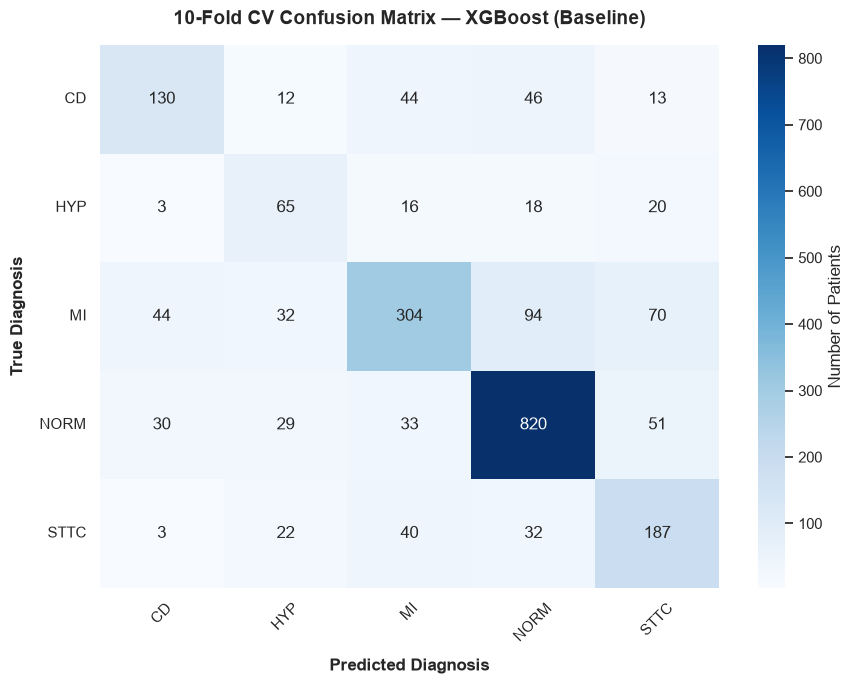

In [43]:
%matplotlib inline

y_true = y_encoded[strat_folds == 10]

plot_confusion_matrix(
    y_true=y_true,
    y_pred=y_pred_xgb_balanced,     # Change this to the predictions of the model you want to visualize
    class_names=encoder.classes_,
    title="10-Fold CV Confusion Matrix — XGBoost (Baseline)",
)

### 6.2 Feature Importance

#### 6.2.1 Feature Importance (Baseline)

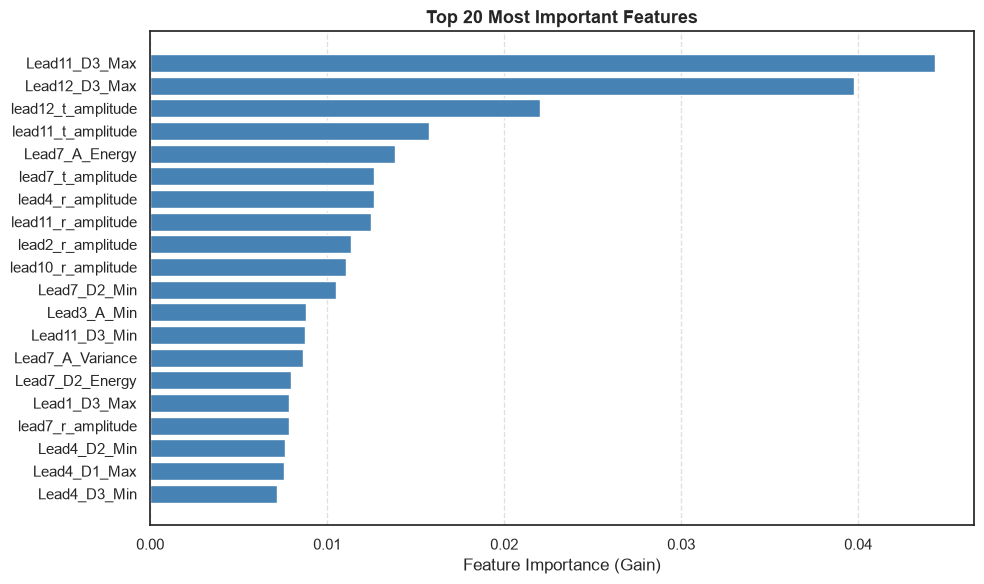

,Feature_Count,Total_Importance,Mean_Importance
Feature Group,,,
DWT (Wavelet),240,0.716329,0.002985
PQRST (Clinical),86,0.283671,0.003298


In [44]:
%matplotlib inline
best_xgb_model = best_xgb_before

importance_df = plot_top_feature_importances(
    model=best_xgb_model,
    feature_names=X_single.columns,
    top_n=20,
    title="Top 20 Most Important Features",
)

# Compare total importance contribution of PQRST vs. DWT features
importance_df["Feature Group"] = importance_df["Feature"].apply(
    lambda f: "DWT (Wavelet)" if f.startswith("Lead") else "PQRST (Clinical)"
)

group_summary = importance_df.groupby("Feature Group")["Importance"].agg(
    Feature_Count="count",
    Total_Importance="sum",
    Mean_Importance="mean",
)

display(group_summary)


#### 6.2.2 Feature Importance (RFE)

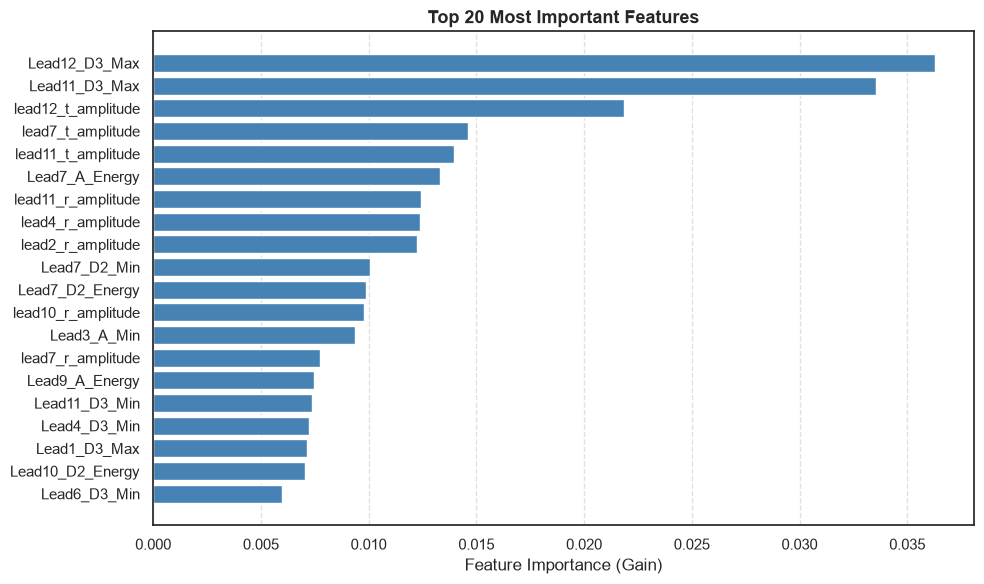

,Feature_Count,Total_Importance,Mean_Importance
Feature Group,,,
DWT (Wavelet),210,0.716296,0.003411
PQRST (Clinical),76,0.283704,0.003733


In [45]:
%matplotlib inline
best_xgb_model = best_xgb_after

importance_df = plot_top_feature_importances(
    model=best_xgb_model,
    feature_names=X_rfe.columns,
    top_n=20,
    title="Top 20 Most Important Features",
)

# Compare total importance contribution of PQRST vs. DWT features
importance_df["Feature Group"] = importance_df["Feature"].apply(
    lambda f: "DWT (Wavelet)" if f.startswith("Lead") else "PQRST (Clinical)"
)

group_summary = importance_df.groupby("Feature Group")["Importance"].agg(
    Feature_Count="count",
    Total_Importance="sum",
    Mean_Importance="mean",
)

display(group_summary)


#### 6.2.3 Feature Importance (Uncorr)

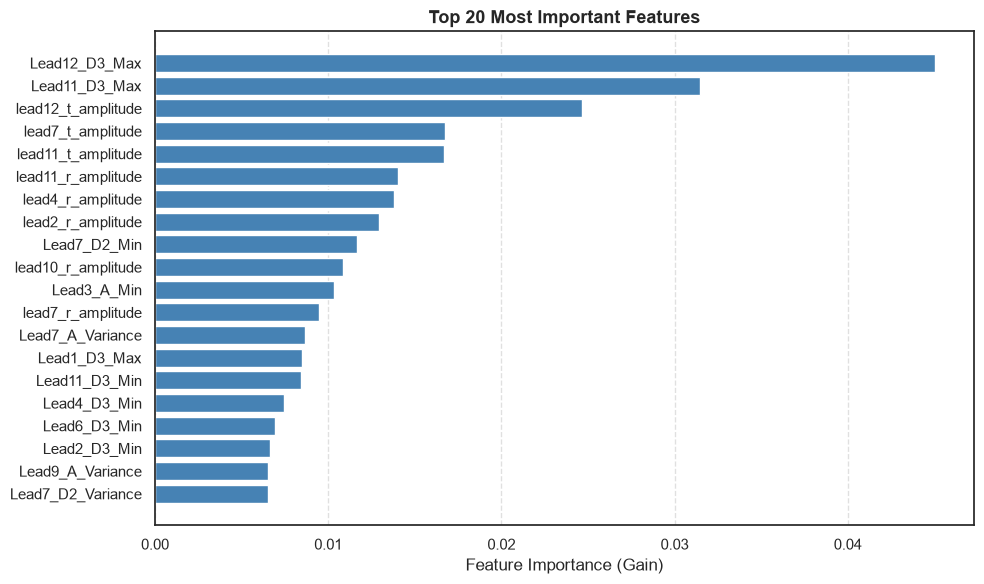

,Feature_Count,Total_Importance,Mean_Importance
Feature Group,,,
DWT (Wavelet),175,0.65926,0.003767
PQRST (Clinical),84,0.34074,0.004056


In [46]:
%matplotlib inline
best_xgb_model = joblib.load(PATH + "models/best_xgb_uncorr.pkl")

importance_df = plot_top_feature_importances(
    model=best_xgb_model,
    feature_names=X_uncorrelated.columns,
    top_n=20,
    title="Top 20 Most Important Features",
)

# Compare total importance contribution of PQRST vs. DWT features
importance_df["Feature Group"] = importance_df["Feature"].apply(
    lambda f: "DWT (Wavelet)" if f.startswith("Lead") else "PQRST (Clinical)"
)

group_summary = importance_df.groupby("Feature Group")["Importance"].agg(
    Feature_Count="count",
    Total_Importance="sum",
    Mean_Importance="mean",
)

display(group_summary)

### 6.3 Feature Correlation Matrix

In [47]:
%matplotlib qt

corr_full = plot_correlation_matrix(
    X_df=X_uncorrelated,
    title="Feature Correlation Matrix After Collinearity Filtering (|r| <= 0.90)",
    pqrst_boundary=None,
)

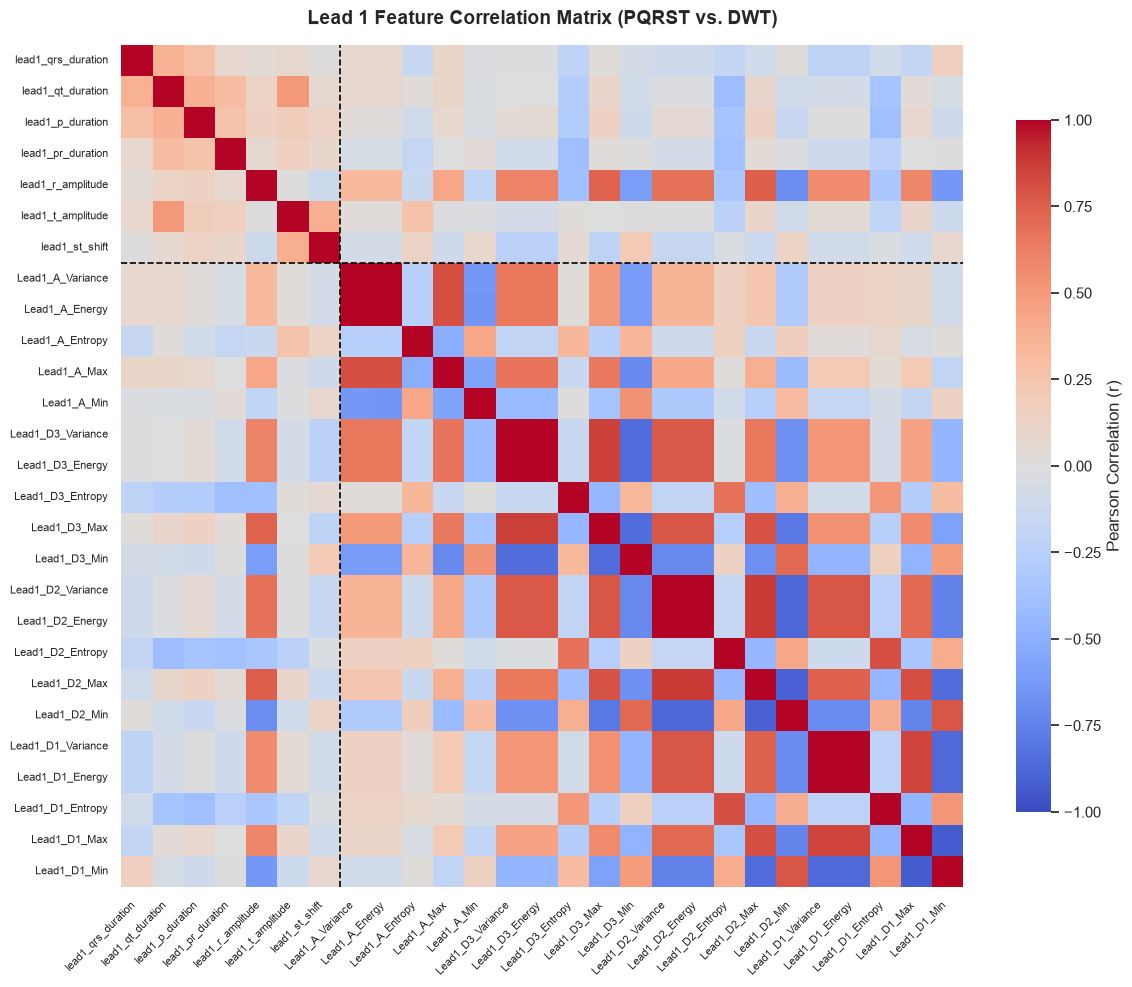

In [48]:
%matplotlib inline
corr_lead1 = plot_correlation_matrix(
    X_df=X_single,
    lead=1,
    annot=False,
)

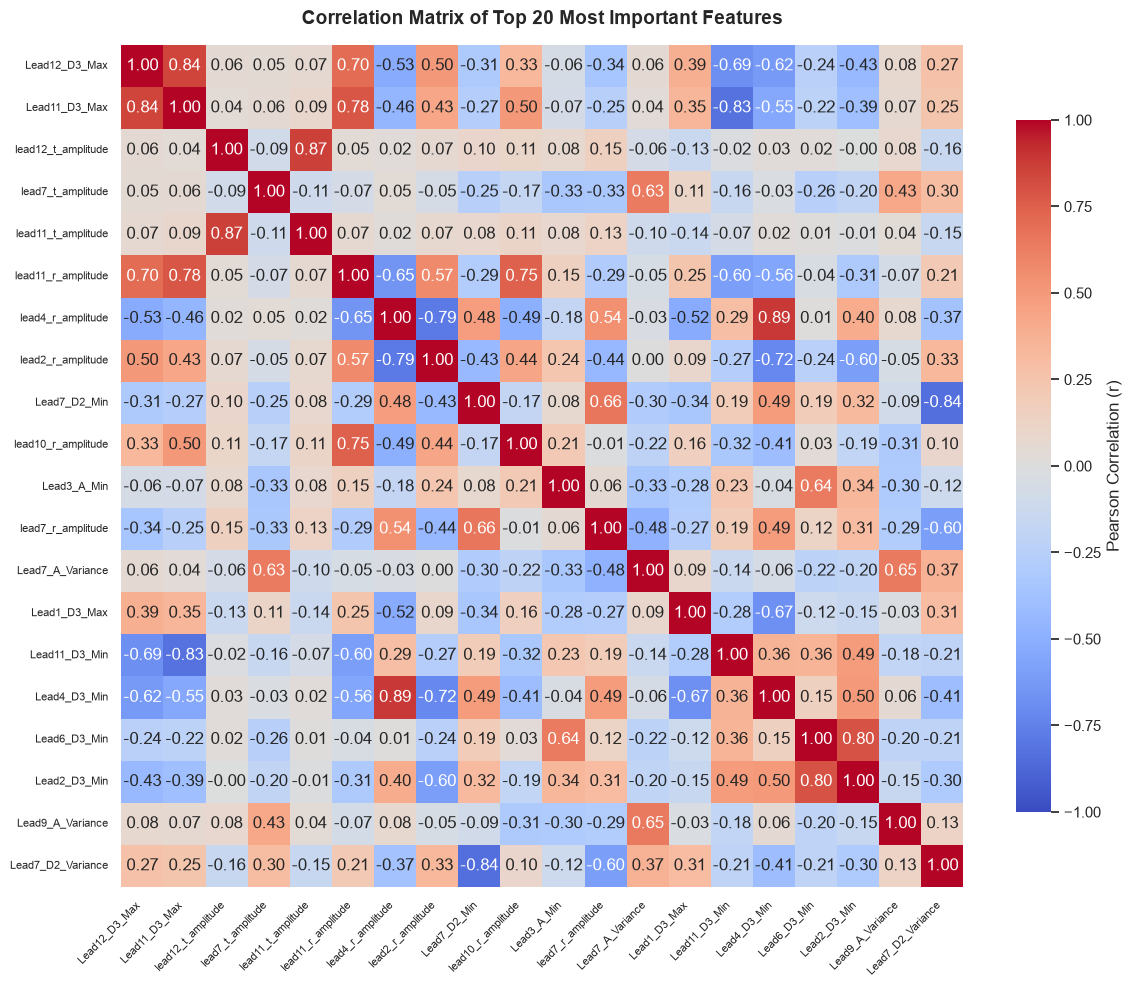

In [49]:
%matplotlib inline
corr_top20 = plot_correlation_matrix(
    X_df=X_single,
    features=importance_df["Feature"].head(20),
    annot=True,
    title="Correlation Matrix of Top 20 Most Important Features",
)